# W10 D4 Daily Challenge: Power Analysis for the Sweet Bytes checkout test

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.power import TTestIndPower

analysis = TTestIndPower()

## Part 1: required sample size per group (effect size 0.2, alpha 0.05, power 0.8)

In [2]:
n = analysis.solve_power(effect_size=0.2, alpha=0.05, power=0.8, ratio=1.0, alternative="two-sided")
print("Required sample size per group:", n)
print("Rounded up:", int(np.ceil(n)))

Required sample size per group: 393.4056930002525
Rounded up: 394


## Part 2: how the sample size changes with the effect size

   effect_size  n_per_group
0          0.1         1571
1          0.2          394
2          0.3          176
3          0.4          100


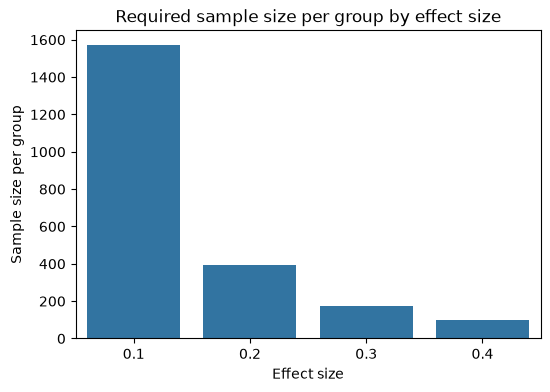

In [3]:
effect_sizes = [0.1, 0.2, 0.3, 0.4]
rows = []
for es in effect_sizes:
    n_es = analysis.solve_power(effect_size=es, alpha=0.05, power=0.8, ratio=1.0, alternative="two-sided")
    rows.append({"effect_size": es, "n_per_group": int(np.ceil(n_es))})
results = pd.DataFrame(rows)
print(results)

plt.figure(figsize=(6, 4))
sns.barplot(data=results, x="effect_size", y="n_per_group")
plt.title("Required sample size per group by effect size")
plt.xlabel("Effect size")
plt.ylabel("Sample size per group")
plt.show()

### Explanation: how and why the sample size changes

As the effect size gets bigger, the sample size needed drops fast: 1,571 per group for 0.1, 394 for 0.2, 176 for 0.3 and 100 for 0.4. The sample size is roughly proportional to 1 divided by the effect size squared, so halving the effect size needs about four times as many people. This happens because a small difference is hard to tell apart from random noise, so you need a lot of data to be confident it is real. A big difference stands out even in a small sample.

## Part 3: explaining it to the bakery team

Think of tasting two cookies. If one is much sweeter, you only need to ask a few people. If the difference is tiny, you need to ask a lot. Power analysis tells us how many customers to include before we start the test. Too few, and a lucky result could fool us. Too many, and we waste time and money while the old checkout keeps running. By choosing the effect size we care about and the sample size we can afford, we make sure the test is big enough to trust and no bigger than needed, so Sweet Bytes can switch checkouts with confidence.